In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [6]:
df = pd.read_csv('weight-height.csv')
df.shape
df.head()
df.info()
df['Gender'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Gender  10000 non-null  object 
 1   Height  10000 non-null  float64
 2   Weight  10000 non-null  float64
dtypes: float64(2), object(1)
memory usage: 234.5+ KB


Gender
Male      5000
Female    5000
Name: count, dtype: int64

In [10]:
male_count  = (df['Gender'] == 'Male').sum()
total_count = df['Gender'].value_counts().sum()
prob = male_count/total_count
prob

np.float64(0.5)

In [11]:
above_70 = (df['Height'] > 70).sum()
prob_tall = above_70 / total_count
prob_tall

np.float64(0.1878)

In [13]:
p_tall = (df['Height'] > 70).mean()
p_tall

np.float64(0.1878)

In [15]:
p_male = (df['Gender'] == 'Male').mean()
p_male

np.float64(0.5)

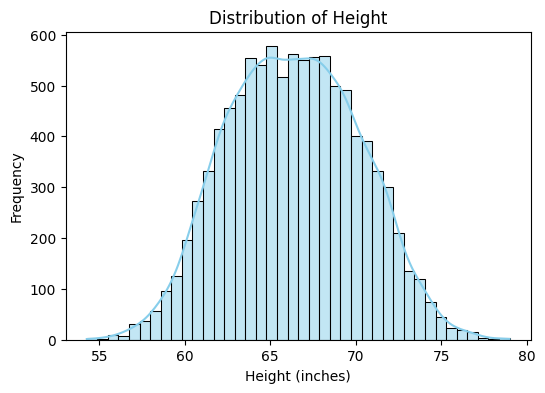

In [20]:
plt.figure(figsize=(6,4))
sns.histplot(df['Height'], bins= 40,kde=True, color="skyblue")
plt.title("Distribution of Height")
plt.xlabel("Height (inches)")
plt.ylabel("Frequency")
plt.show()

In [23]:
df.describe()

,Height,Weight
count,10000.000000,10000.000000
mean,66.367560,161.440357
std,3.847528,32.108439
min,54.263133,64.700127
25%,63.505620,135.818051
50%,66.318070,161.212928
75%,69.174262,187.169525
max,78.998742,269.989699


In [25]:
height_median = df['Height'].median()
weight_median = df['Weight'].median()
height_median, weight_median

(np.float64(66.31807008178464), np.float64(161.21292769948298))

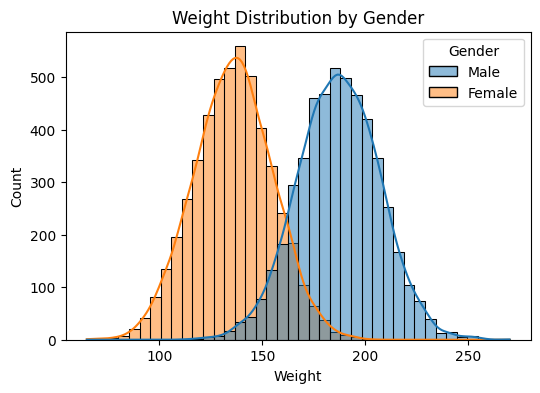

In [27]:
plt.figure(figsize=(6,4))
sns.histplot(data=df, x="Weight", hue="Gender", bins=40, kde=True)
plt.title("Weight Distribution by Gender")
plt.show()

In [ ]:
mean_h = df['Height'].mean()
std_h = df['Height'].std()

within_1sd = df[(df['Height'] > mean_h - std_h) & (df['Height'] < mean_h + std_h)]
within_2sd = df[(df['Height'] > mean_h - 2 * std_h) & (df['Height'] < mean_h + 2 * std_h)]

within_1sd = {len(within_1sd)/len(df) * 100}
within_2sd = {len(within_2sd)/len(df) * 100}

within_1sd, within_2sd

({65.27}, {96.52})

In [33]:
x = 74
z = (x-mean_h) / std_h
z

np.float64(1.9837256559530698)

In [37]:
p_below_74 = stats.norm.cdf(74, loc=mean_h, scale=std_h)
p_below_74 

p_above_74 = 1 - p_below_74
p_above_74

np.float64(0.023643215923336958)

## Sampling & The Central Limit Theorem

In [40]:
sample = df['Height'].sample(n=30, random_state=42)
sample_mean = sample.mean()
sample_mean, mean_h

(np.float64(66.53045344103077), np.float64(66.36755975482124))

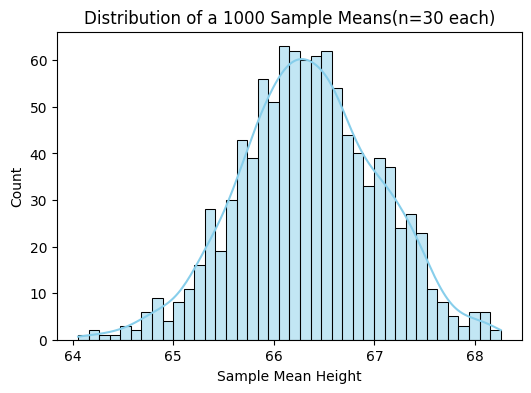

In [49]:
sample_means = []

for i in range(1000):
    sample = df['Height'].sample(n=30, replace=True)
    sample_means.append(sample.mean())

# sample_means

plt.figure(figsize=(6,4))
sns.histplot(sample_means, bins=40, kde=True, color='skyblue')
plt.title("Distribution of a 1000 Sample Means(n=30 each)")
plt.xlabel("Sample Mean Height")
plt.show()